In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [80]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<h1>EDA(Exploratory Data Analysis )</h1>

In [81]:
df.shape

(1338, 7)

In [82]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [83]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [84]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [85]:
df.duplicated().sum()


np.int64(1)

In [86]:
df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [87]:
df = df.drop_duplicates()

In [88]:
df.duplicated().sum()

np.int64(0)

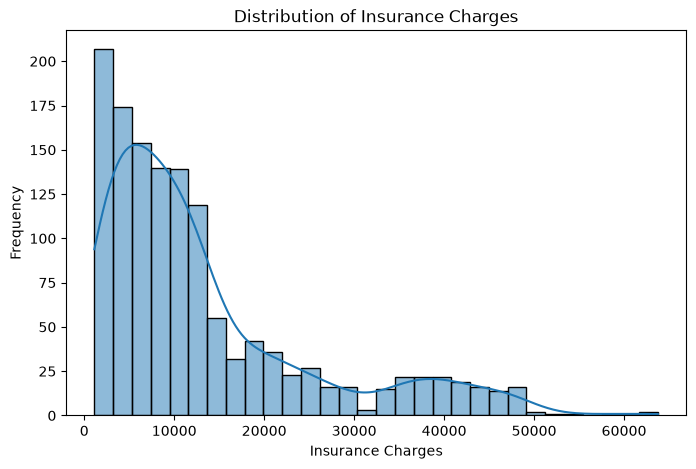

In [89]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="charges",bins=30,kde=True)
plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")
plt.show()

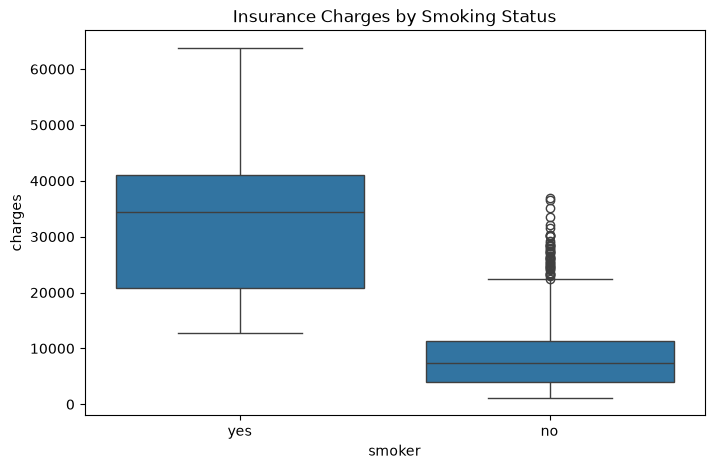

In [90]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="smoker", y="charges")
plt.title("Insurance Charges by Smoking Status")
plt.show()

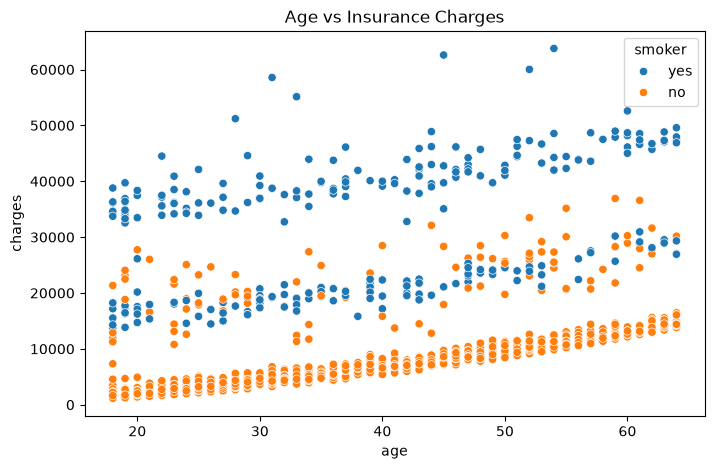

In [91]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="age",y="charges",hue="smoker")
plt.title("Age vs Insurance Charges")
plt.show()

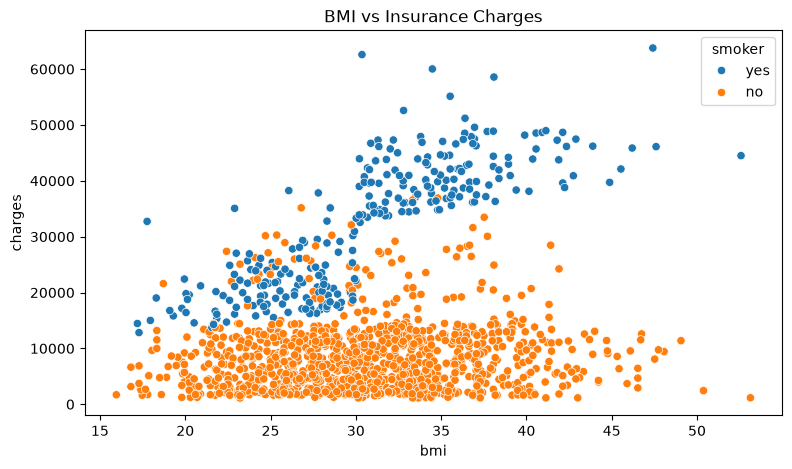

In [92]:
plt.figure(figsize=(9, 5))

sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")

plt.title("BMI vs Insurance Charges")
plt.show()

<Figure size 900x500 with 0 Axes>

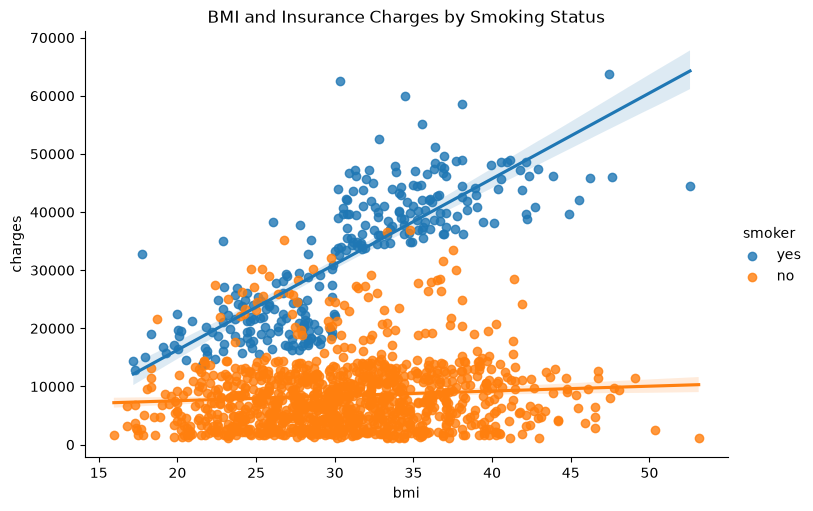

In [93]:
plt.figure(figsize=(9, 5))

sns.lmplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker",
    height=5,
    aspect=1.5
)

plt.title("BMI and Insurance Charges by Smoking Status")
plt.show()

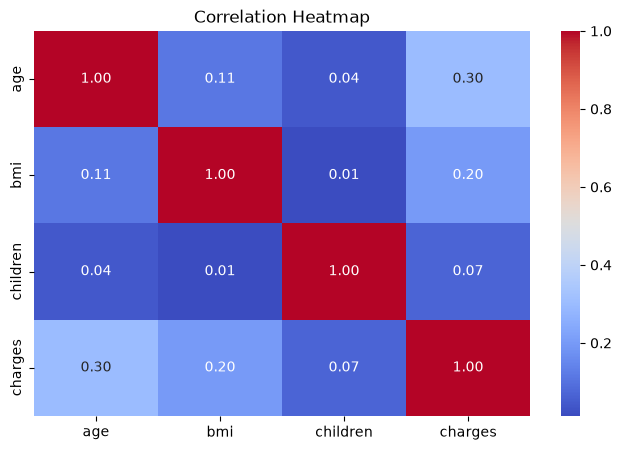

In [94]:
corr_matrix = df.select_dtypes(include="number").corr()
plt.figure(figsize=(8,5))
sns.heatmap(data=corr_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [95]:
corr_matrix["charges"].sort_values(ascending=False)


charges     1.000000
age         0.298308
bmi         0.198401
children    0.067389
Name: charges, dtype: float64

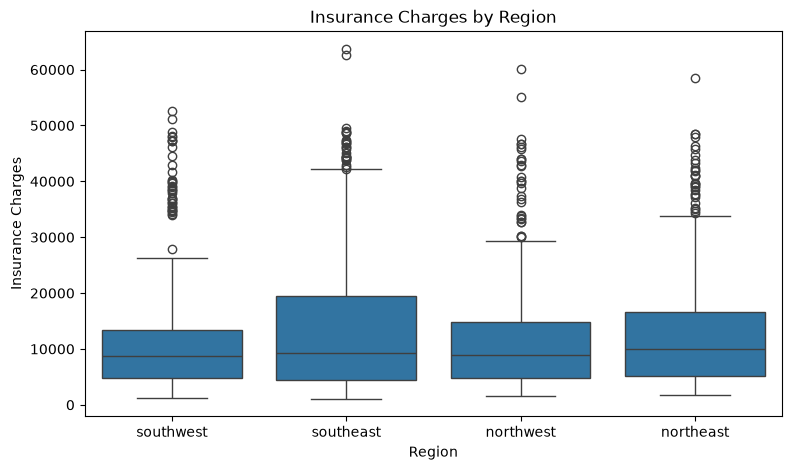

In [96]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="region", y="charges")

plt.title("Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Insurance Charges")

plt.show()

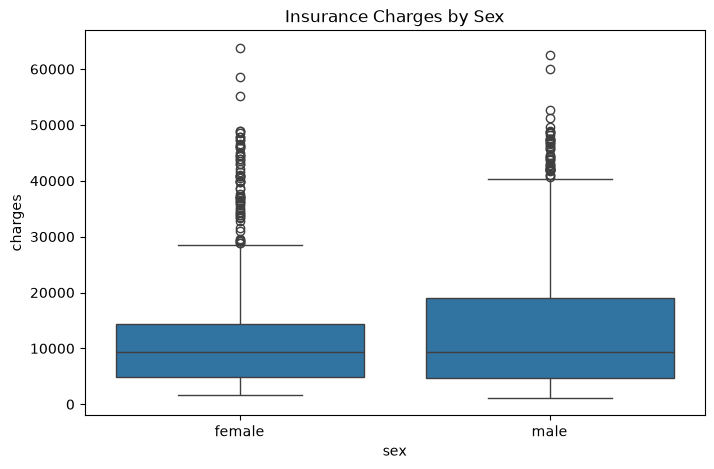

In [97]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="sex", y="charges")

plt.title("Insurance Charges by Sex")
plt.show()

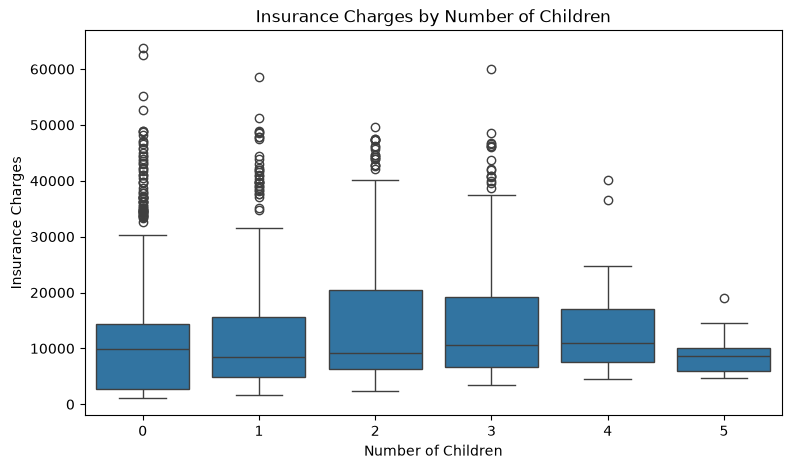

In [98]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="children", y="charges")

plt.title("Insurance Charges by Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Insurance Charges")

plt.show()

<h1>Data Preprocessing</h1>

In [99]:
X = df.drop("charges",axis=1)
y = df["charges"]

In [100]:
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [101]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [102]:
from sklearn.model_selection import train_test_split


In [103]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=69)

In [104]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1069, 6)
(268, 6)
(1069,)
(268,)


<h1>One Hot Encoding</h1>

In [105]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder()


In [106]:
categorical_features = ["sex","smoker","region"]
X_train[categorical_features].head()

,sex,smoker,region
55,male,yes,northwest
444,male,yes,northwest
852,female,yes,northeast
492,female,no,northeast
967,male,no,northwest


In [107]:
encoder.fit(X_train[categorical_features])

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent

In [108]:
X_train_encoded = encoder.transform(X_train[categorical_features])
print(X_train_encoded.shape)

(1069, 8)


In [109]:
encoded_cols = encoder.get_feature_names_out(categorical_features)
encoded_train_df = pd.DataFrame(X_train_encoded.toarray(),columns=encoded_cols,index=X_train.index)
encoded_train_df.head()

,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
55,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
444,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
852,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
492,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
967,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


In [110]:
numerical_feature = ["age", "bmi", "children"]
X_train_numerical = X_train[numerical_feature]
X_train_prepared = pd.concat([X_train_numerical,encoded_train_df],axis=1)
X_train_prepared.head()


,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
55,58,36.955,2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
444,56,26.695,1,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
852,46,35.530,0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
492,18,25.080,0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
967,44,25.365,1,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


In [111]:
X_test_encoded = encoder.transform(X_test[categorical_features])
encoded_test_df = pd.DataFrame(X_test_encoded.toarray(),columns=encoded_cols,index=X_test.index)
X_test_numerical = X_test[numerical_feature]
X_test_prepared = pd.concat([encoded_test_df,X_test_numerical],axis=1)

In [112]:
X_test_prepared.shape

(268, 11)

In [117]:
X_test_prepared = X_test_prepared[X_train_prepared.columns]

<h1>Linear Regression</h1>

In [113]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_prepared,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 251.04, 358.34, 462.88,..., 171.6 ,-477.6 ,-568.81]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['age','bmi','children',...,'region_northwest','region_southeast', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1071
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


Model Testing

In [114]:
y_train_pred = model.predict(X_train_prepared)

In [115]:
comparison_train = pd.DataFrame({
    "Actual Charges": y_train,
    "Predicted Charges": y_train_pred
})
comparison_train.head()

,Actual Charges,Predicted Charges
55,47496.49445,39604.739588
444,26109.32905,34963.164007
852,42111.66470,36151.620192
492,2196.47320,1535.012221
967,7518.02535,7631.312578


In [118]:
y_test_pred = model.predict(X_test_prepared)
comparison_test = pd.DataFrame({
    "Actual Charges": y_test,
    "Predicted Charges": y_test_pred
})
comparison_test.head(10)

,Actual Charges,Predicted Charges
606,3558.62025,3828.423670
979,4889.03680,6435.733612
701,9541.69555,16615.166088
1045,21880.82000,31740.183527
361,4751.07000,6471.636719
490,1748.77400,3144.697029
69,17663.14420,27237.672519
539,27346.04207,10923.293373
336,12142.57860,10670.268021
45,20630.28351,13466.318117


In [119]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_test_pred)

print("MAE:", mae)

MAE: 4512.776080731104


In [120]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("RMSE:", rmse)

RMSE: 6718.611986003131


<h1>Baseline Model</h1>

In [121]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="median")

baseline_model.fit(X_train_prepared, y_train)

baseline_pred = baseline_model.predict(X_test_prepared)

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)

Baseline MAE: 8675.822420858209
